# Step 8 — 0.6B 实验毕业决策

汇总所有 stage report，给出是否值得升级到 1.7B 的明确结论。

**毕业条件：** predictor discrimination、remaining-length signal、controller 至少部分 budget 不输 fixed baseline。任何 operational gate 失败都应先修流水线。

In [1]:
# @title Step 08.1 — 初始化运行环境
from pathlib import Path
import gc
import importlib.util
import json
import os
import shutil
import subprocess
import sys

REPO = Path("/content/ZIP-RC-Colab")
ZIP_PY = Path("/content/mamba/envs/zip/bin/python")
REPO_URL = "https://github.com/wtree101/ZIP-RC-Colab.git"
REPO_BRANCH = "main"
SYNC_REPO = True

if not REPO.exists():
    subprocess.run(["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO)], check=True)
elif SYNC_REPO:
    subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only", "origin", REPO_BRANCH], check=True)

if not ZIP_PY.exists():
    raise FileNotFoundError(
        f"未找到 {ZIP_PY}。请先建立 ZIP-RC 的 mamba 环境，再重新运行本 Notebook。"
    )

kernel_required = ["torch", "numpy", "pandas", "pyarrow", "matplotlib", "sklearn", "psutil"]
kernel_missing = [name for name in kernel_required if importlib.util.find_spec(name) is None]
if kernel_missing:
    raise ModuleNotFoundError(f"Colab kernel 缺少可视化依赖: {kernel_missing}")

env_check = subprocess.run(
    [
        str(ZIP_PY),
        "-c",
        (
            "import importlib.util, json; "
            "mods=['torch','vllm','transformers','datasets','pandas','pyarrow','tqdm']; "
            "print(json.dumps([m for m in mods if importlib.util.find_spec(m) is None]))"
        ),
    ],
    check=True,
    capture_output=True,
    text=True,
)
env_missing = json.loads(env_check.stdout.strip())
if env_missing:
    raise ModuleNotFoundError(f"zip mamba 环境缺少依赖: {env_missing}")

sys.path.insert(0, str(REPO / "notebooks"))
from ziprc_notebook_utils import (
    gate,
    gate_frame,
    load_config,
    model_artifacts_exist,
    progress_frame,
    read_jsonl,
    require_columns,
    rolling_edges,
    run_repo,
    save_stage_report,
    select_best_cuda_device,
)

selected_gpu = select_best_cuda_device()
os.environ["ZIPRC_PYTHON"] = str(ZIP_PY)
os.environ["PATH"] = f"{Path.home() / '.local/bin'}{os.pathsep}{os.environ['PATH']}"
PROXY_URL = os.environ.get("ZIP_RC_PROXY", "http://sccpu8.cse.ust.hk:7890").strip()
if PROXY_URL:
    for proxy_variable in ("HTTP_PROXY", "HTTPS_PROXY", "ALL_PROXY"):
        os.environ[proxy_variable] = PROXY_URL
        os.environ[proxy_variable.lower()] = PROXY_URL
    os.environ["NO_PROXY"] = ""
    os.environ["no_proxy"] = ""

import matplotlib.pyplot as plt
import pandas as pd
import psutil
import torch
from IPython.display import display

print("Repository:", REPO)
print("ZIP Python:", ZIP_PY)
print("Selected GPU:", selected_gpu or "unchanged")

CONFIG = load_config(REPO)
print("Experiment:", CONFIG["experiment_name"])


Repository: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab
Experiment: qwen3_0.6b_ziprc_small_validation


In [ ]:
# @title Step 08.2 — 查看持久化进度
runtime_progress = progress_frame(REPO)
print("持久化进度快照：")
display(runtime_progress if not runtime_progress.empty else pd.DataFrame([{"状态": "尚无进度记录"}]))

,stage,report_exists,operational,scientific
0,00_memory_and_config,True,True,True
1,01_pilot_generation,True,True,False
2,02_pilot_quality,True,False,False
3,03_training_data,True,False,False
4,04_prompt_split,True,True,True
5,05_predictor_training,True,True,True
6,06_predictor_evaluation,True,True,False
7,07_controller_comparison,True,True,True


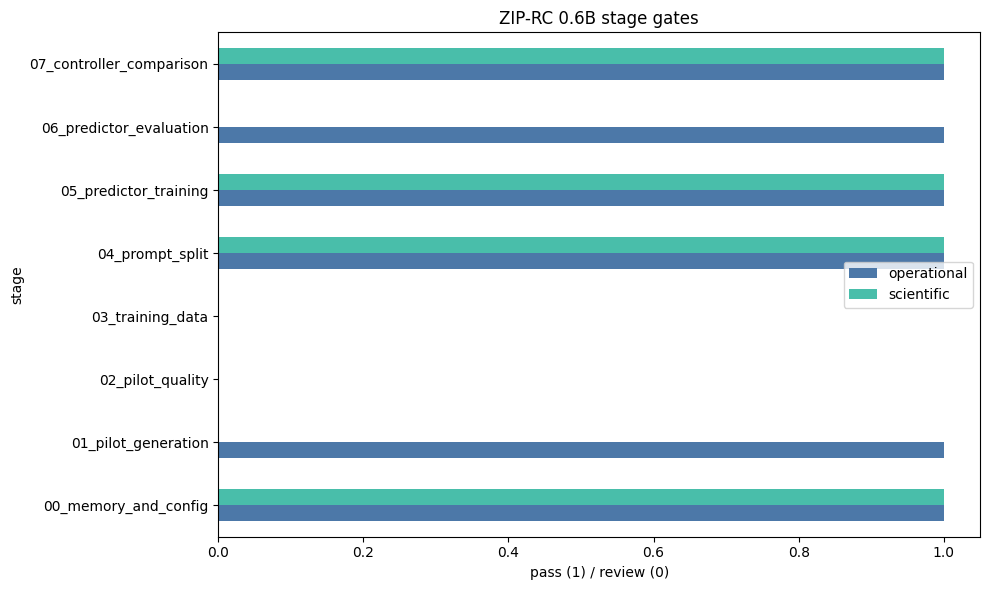

In [2]:
# @title Step 08.3 — 汇总全部 stage reports
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

report_dir = REPO / "artifacts" / "stage_reports"
expected = [
    "00_memory_and_config", "01_pilot_generation", "02_pilot_quality",
    "03_training_data", "04_prompt_split", "05_predictor_training",
    "06_predictor_evaluation", "07_controller_comparison",
]
reports = {}
for name in expected:
    path = report_dir / f"{name}.json"
    reports[name] = json.loads(path.read_text(encoding="utf-8")) if path.exists() else None

summary = pd.DataFrame([
    {
        "stage": name,
        "report_exists": report is not None,
        "operational": report["operational_passed"] if report else False,
        "scientific": report["scientific_passed"] if report else False,
    }
    for name, report in reports.items()
])
display(summary)

ax = summary.set_index("stage")[["operational", "scientific"]].astype(int).plot.barh(figsize=(10, 6), color=["#4c78a8", "#49beaa"])
ax.set(xlim=(0, 1.05), title="ZIP-RC 0.6B stage gates", xlabel="pass (1) / review (0)")
plt.tight_layout()
plt.show()

In [3]:
# @title Step 08.4 — 作出是否升级到 1.7B 的决定
operational_ok = bool(summary["report_exists"].all() and summary["operational"].all())
predictor_ok = bool(summary.loc[summary["stage"] == "06_predictor_evaluation", "scientific"].iloc[0]) if reports["06_predictor_evaluation"] else False
controller_ok = bool(summary.loc[summary["stage"] == "07_controller_comparison", "scientific"].iloc[0]) if reports["07_controller_comparison"] else False
graduate = operational_ok and predictor_ok and controller_ok

if graduate:
    display(Markdown("## ✅ 建议升级到 Qwen3-1.7B\n0.6B 已证明 predictor 和 controller 均有可用信号。"))
elif not operational_ok:
    display(Markdown("## ⛔ 暂停扩模\n至少一个流水线阶段未妥善完成，请先处理 operational gate。"))
else:
    display(Markdown("## ⚠️ 保持 0.6B 调试\n流水线正常，但 discrimination / length / controller 信号尚未全部达到毕业条件。"))

failed_gates = []
for stage, report in reports.items():
    if report:
        failed_gates.extend({"stage": stage, **item} for item in report["gates"] if not item["passed"])
display(pd.DataFrame(failed_gates) if failed_gates else pd.DataFrame([{"status": "all gates passed"}]))

checks = [
    gate("所有阶段报告存在", summary["report_exists"].all(), f"{summary['report_exists'].sum()}/{len(summary)}"),
    gate("所有 operational gates 通过", operational_ok, "流水线完整性"),
    gate("Predictor 达标", predictor_ok, "discrimination + incorrect recall + length", kind="scientific"),
    gate("Controller 达标", controller_ok, "至少出现一个 Pareto signal", kind="scientific"),
]
display(gate_frame(checks))
save_stage_report(REPO, "08_graduation_decision", checks, {"graduate_to_1_7b": graduate})

## ⛔ 暂停扩模
至少一个流水线阶段未妥善完成，请先处理 operational gate。

,stage,name,passed,detail,kind
0,01_pilot_generation,Finished rate ≥95%,False,92.5%,scientific
1,01_pilot_generation,撞输出上限 <5%,False,7.5%,scientific
2,02_pilot_quality,理想正确率 30%–70%,False,accuracy=78.8%,scientific
3,02_pilot_quality,Finished rows 的 grader 输出全部有效,False,valid=359/370,operational
4,03_training_data,Finished rate ≥95%,False,92.1%,scientific
5,03_training_data,截断 <5%,False,7.9%,scientific
6,03_training_data,Finished rows 的 grader 输出全部有效,False,valid=3565/3685,operational
7,06_predictor_evaluation,Incorrect recall ≥0.50,False,0.329,scientific


,类型,检查项,状态,说明
0,operational,所有阶段报告存在,✅ 通过,8/8
1,operational,所有 operational gates 通过,⚠️ 检查,流水线完整性
2,scientific,Predictor 达标,⚠️ 检查,discrimination + incorrect recall + length
3,scientific,Controller 达标,✅ 通过,至少出现一个 Pareto signal


PosixPath('/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/stage_reports/08_graduation_decision.json')